
## 2.1 高校剖析

对有代表性的系统进行测试，找出速度缓慢(RAM多，大量磁盘或网络IO)

## 2.2 Julia集合


## 2.3 计算整个Julia集合

## 2.4 简单计时方法

## 2.5 unix time

## 2.6 cProfile

## 2.7 snakeviz

## 2.8 line_profile

## 2.9 memory_profiel

## 2.10 Pysy

## 2.11 字节码

### dis

### 复杂度随方法而异 



In [ ]:
import time

x1, x2, y1, y2 = -1.8, 1.8, -1.8, 1.8
c_real, c_imag = -0.62772, -0.42193


def calculate_z_serial(max_iter, zs, cs):
    output = [0] * len(zs)
    for i in range(len(zs)):
        n = 0
        z = zs[i]
        c = cs[i]
        while abs(z) < 2 and n < max_iter:
            z = z * z + c
            n += 1
        output[i] = n
    return output


def call_pure(desired_width, max_iteration):
    x_step = (x2 - x1) / desired_width
    y_step = (y2 - y1) / desired_width

    x = []
    y = []

    ycoord = y1
    while ycoord < y2:
        y.append(ycoord)
        ycoord += y_step

    xcoord = x1
    while xcoord < x2:
        x.append(xcoord)
        xcoord += x_step

    zs = []
    cs = []

    for ycoord in y:
        for xcoord in x:
            zs.append(complex(xcoord, ycoord))
            cs.append(complex(c_real, c_imag))

    print("Length of x:", len(x))
    print("Total elements:", len(zs))

    start_time = time.time()
    output = calculate_z_serial(max_iteration, zs, cs)
    end_time = time.time()

    print(f"cal take {end_time - start_time} seconds")
    return output


result = call_pure(10, 3)
print(result[:20])

Length of x: 11
Total elements: 121
cal take 6.079673767089844e-05 seconds
[0, 0, 0, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1]


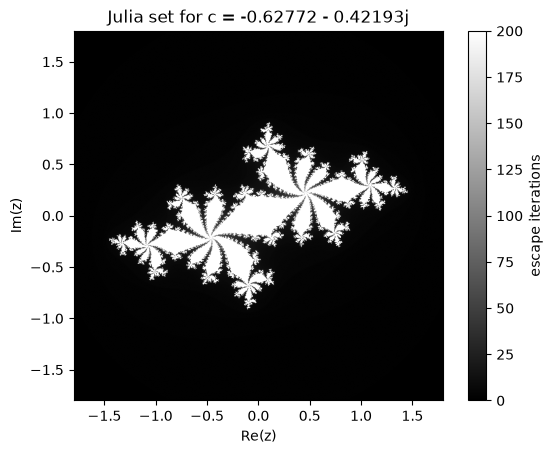

In [18]:
# %pip install matplotlib

import numpy as np
import matplotlib.pyplot as plt

x1, x2, y1, y2 = -1.8, 1.8, -1.8, 1.8
c = complex(-0.62772, -0.42193)

def julia_escape(width=600, height=600, maxiter=200):
    xs = np.linspace(x1, x2, width)
    ys = np.linspace(y1, y2, height)
    out = np.zeros((height, width), dtype=int)

    for j, y in enumerate(ys):
        for i, x in enumerate(xs):
            z = complex(x, y)
            n = 0
            while abs(z) < 2 and n < maxiter:
                z = z * z + c
                n += 1
            out[j, i] = n
            # print(f"j={j}, i={i}, val={out[j, i]}")

    return out

img = julia_escape(width=600, height=600, maxiter=200)

plt.imshow(
    img,
    extent=[x1, x2, y1, y2],
    origin="lower",
    cmap="gray"
)
plt.colorbar(label="escape iterations")
plt.xlabel("Re(z)")
plt.ylabel("Im(z)")
plt.title("Julia set for c = -0.62772 - 0.42193j")
plt.show()

In [ ]:
# 2.4 wrap timer

import time
from functools import wraps

def timefn(fn):
    @wraps(fn)
    # def f(*args, **kwargs) --> 打包：多余位置参数(args)→tuple，多余关键字参数(kwargs)→dict
    def measure_time(*args, **kwargs):
        start_time = time.time()
        result = fn(*args, **kwargs)
        end_time = time.time()
        print(f"@timefn: {fn.__name__} took {end_time-start_time} seconds")
        return result
    return measure_time

@timefn
def sample():
    time.sleep(2)
    print('function done')

sample()


function done
@timefn: sample took 2.000277280807495 seconds


In [24]:
%timeit sum(range(10))

87.2 ns ± 0.323 ns per loop (mean ± std. dev. of 7 runs, 10,000,000 loops each)
